[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/exercicios/modelo_relatorio.ipynb)

# Relatório de HPC — modelo
> 🎬 **Vídeo (1 min):** [Como fazer o relatório: speedup, eficiência e gráficos](https://lucaswastaken.github.io/Openhardware-hpc/#v11)

**Nome:** …  **Exercício:** …  **Tecnologia:** …

Como usar: troque as funções `serial` e `paralela` (seções 2 e 3) pelas suas. O resto — medir, conferir, calcular speedup/eficiência e desenhar os gráficos — já está pronto. Apague este exemplo (soma de $\sqrt{|\sin x|}$) quando colocar o seu.

In [1]:
import os, sys, time, platform
import numpy as np
import matplotlib.pyplot as plt

try:
    import cupy as cp
    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:
    cp, GPU = None, False

def sincroniza():
    if GPU: cp.cuda.Device().synchronize()

def medir(f, *args, repeticoes=5, **kw):
    """Aquece uma vez, depois mede `repeticoes` vezes e devolve (menor tempo, resultado)."""
    r = f(*args, **kw); sincroniza()
    tempos = []
    for _ in range(repeticoes):
        sincroniza(); t = time.perf_counter(); r = f(*args, **kw); sincroniza()
        tempos.append(time.perf_counter() - t)
    return min(tempos), r

print(f"Python {platform.python_version()} · {os.cpu_count()} núcleos lógicos · GPU: {GPU} · Colab: {'google.colab' in sys.modules}")

C:\Users\lucas\Documents\GitHub\Openhardware-hpc\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Python 3.12.13 · 12 núcleos lógicos · GPU: True · Colab: False


## 1. Problema
*(2–3 linhas: o que é calculado, aplicação em engenharia, tamanho do problema)*

## 2. Versão serial (referência)

In [2]:
def serial(x):
    s = 0.0
    for v in x:
        s += abs(np.sin(v)) ** 0.5
    return s

x = np.random.default_rng(0).random(200_000) * 100
t_serial, ref = medir(serial, x, repeticoes=2)
print(f"serial: {t_serial:.3f} s  →  {ref:.6f}")

serial: 0.073 s  →  152895.639752


## 3. Versão paralela
*(explique como dividiu o trabalho: por blocos? por elemento? quantos processos/threads/blocos de GPU?)*

A função recebe `p`, o número de trabalhadores (processos, threads, `n_jobs`…). Para GPU, deixe `p` fixo e varie o **tamanho** na seção 5.

In [3]:
from numba import njit, prange, set_num_threads

@njit(parallel=True)
def _kernel(x):
    s = 0.0
    for i in prange(x.size):
        s += abs(np.sin(x[i])) ** 0.5
    return s

def paralela(x, p):
    set_num_threads(p)
    return _kernel(x)

t, r = medir(paralela, x, os.cpu_count())
assert np.isclose(r, ref, rtol=1e-9), (r, ref)       # CORREÇÃO: sempre confira com a referência
print(f"paralela: {t:.4f} s  →  {r:.6f}  ✓ confere com a serial")

paralela: 0.0004 s  →  152895.639752  ✓ confere com a serial


## 4. Escalabilidade forte (tamanho fixo, varia p)

  p  tempo [s]  speedup eficiência
  1     0.2316     1.00       100%
  2     0.1320     1.76        88%
  4     0.0819     2.83        71%
  8     0.0510     4.54        57%


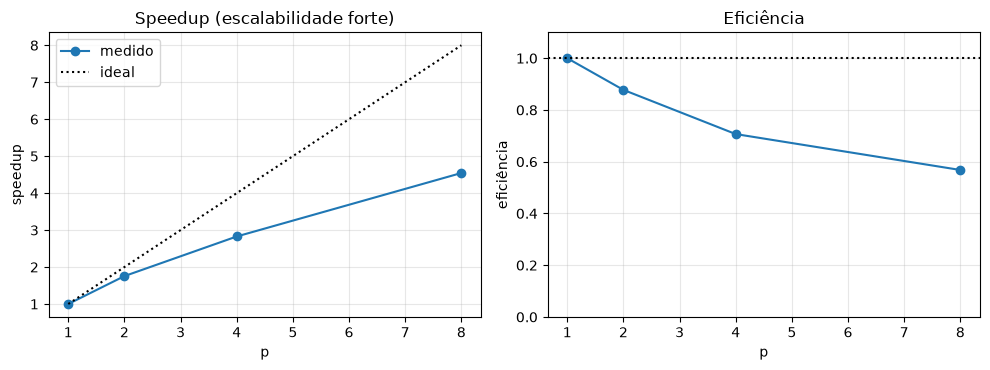

In [4]:
ps = [p for p in (1, 2, 4, 8, 16, 32) if p <= os.cpu_count()]
x_forte = np.random.default_rng(1).random(20_000_000) * 100
T = {p: medir(paralela, x_forte, p)[0] for p in ps}
S = {p: T[1] / T[p] for p in ps}
E = {p: S[p] / p for p in ps}

print(f"{'p':>3} {'tempo [s]':>10} {'speedup':>8} {'eficiência':>10}")
for p in ps:
    print(f"{p:>3} {T[p]:>10.4f} {S[p]:>8.2f} {E[p]:>10.0%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(ps, [S[p] for p in ps], "o-", label="medido"); a1.plot(ps, ps, "k:", label="ideal")
a1.set(xlabel="p", ylabel="speedup", title="Speedup (escalabilidade forte)"); a1.legend()
a2.plot(ps, [E[p] for p in ps], "o-"); a2.axhline(1, color="k", ls=":")
a2.set(xlabel="p", ylabel="eficiência", ylim=(0, 1.1), title="Eficiência")
for a in (a1, a2): a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("escalabilidade_forte.png", dpi=150); plt.show()

## 5. Escalabilidade fraca (tamanho cresce com p) — ou, na GPU, tempo × tamanho

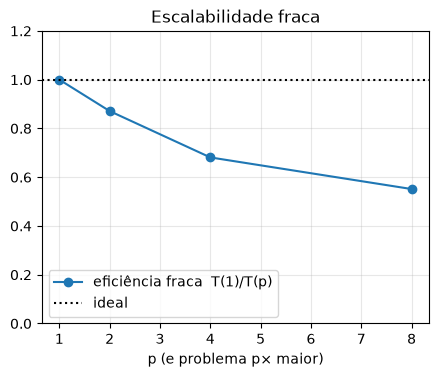

In [5]:
por_trabalhador = 5_000_000
Tf = {p: medir(paralela, np.random.default_rng(p).random(por_trabalhador * p) * 100, p)[0] for p in ps}
plt.figure(figsize=(5, 3.8))
plt.plot(ps, [Tf[1] / Tf[p] for p in ps], "o-", label="eficiência fraca  T(1)/T(p)")
plt.axhline(1, color="k", ls=":", label="ideal")
plt.xlabel("p (e problema p× maior)"); plt.ylim(0, 1.2); plt.legend(); plt.grid(alpha=.3)
plt.title("Escalabilidade fraca"); plt.savefig("escalabilidade_fraca.png", dpi=150); plt.show()

## 6. Análise
- **Gargalo:** cálculo, memória, transferências CPU↔GPU ou overhead de criar/sincronizar trabalhadores? Justifique com os números.
- **Amdahl:** estime a fração serial a partir do speedup (Karp–Flatt: $e = (1/S - 1/p)/(1 - 1/p)$).
- **Banda de memória** (se for limitado por memória): bytes lidos+escritos / tempo, em GB/s.

## 7. Conclusões e limitações
*(3–4 linhas)*